Cell 1 – Markdown

# 01 – DATA UNDERSTANDING

Mục tiêu:
1. Khảo sát cấu trúc toàn bộ dữ liệu.
2. Profiling từng bảng và từng thuộc tính.
3. Xây dựng Data Dictionary.
4. Phân tích phân phối và thống kê mô tả.
5. Phân tích doanh số theo thời gian.
6. Phân tích đặc điểm SKU.
7. Phân tích tồn kho, giá bán và khuyến mãi.
8. Khảo sát quan hệ giữa các bảng.

Nguồn: Raw dataset từ 00_data_collection.ipynb.

Nguyên tắc:
- Chưa xử lý dữ liệu thiếu.
- Chưa loại bỏ ngoại lai.
- Chưa xóa bản ghi trùng.
- Không biến tuần không có giao dịch thành tuần bán bằng 0.


Cell 1 – Khởi tạo và đọc dữ liệu

In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json
import warnings
import os

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

CURRENT_DIR = Path.cwd().resolve()
candidates = [CURRENT_DIR, *CURRENT_DIR.parents]

for env_name in ("VSCODE_CWD", "GITHUB_WORKSPACE"):
    env_dir = os.environ.get(env_name)
    if env_dir:
        candidates.append(Path(env_dir).resolve())

PROJECT_DIR = next(
    (candidate for candidate in candidates if (candidate / "data" / "raw").is_dir()),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục project chứa data/raw/. "
        "Hãy mở VS Code tại thư mục SKU-Weekly-Sales-Forecasting "
        "hoặc đặt kernel working directory về thư mục project. "
        f"Thư mục hiện tại: {CURRENT_DIR}"
    )

RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "reports"
PLOT_DIR = PROJECT_DIR / "plots"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

def read_csv_safely(file_path):
    for encoding in ["utf-8-sig", "utf-8", "cp1252", "latin1"]:
        try:
            return pd.read_csv(
                file_path,
                encoding=encoding,
                low_memory=False
            )
        except Exception:
            pass
    raise ValueError(f"Không đọc được file: {file_path}")


csv_files = sorted(RAW_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "Không có CSV trong data/raw/. "
        "Hãy chạy Notebook 00 và kiểm tra lại thư mục dữ liệu."
    )

tables = {
    file.stem: read_csv_safely(file)
    for file in csv_files
}

print("Số bảng:", len(tables))
print("Tên bảng:", list(tables.keys()))

Số bảng: 27
Tên bảng: ['Brands', 'BrandSubcategoryMap', 'Categories', 'CustomerReturns', 'Customers', 'Governorates', 'InventoryBalances', 'InventoryMovements', 'Locations', 'PaymentMethods', 'Payments', 'Products', 'ProductVariants', 'Promotions', 'PurchaseOrderLines', 'PurchaseOrders', 'PurchaseReceiptLines', 'PurchaseReceipts', 'PurchaseReturns', 'SalesChannels', 'SalesOrderLines', 'SalesOrders', 'Shipments', 'ShippingProviders', 'SKUSuppliers', 'Subcategories', 'Suppliers']


Cell 2 – Profiling từng bảng

In [13]:
table_profiles = []
column_profiles = []
data_dictionary_rows = []

for table_name, df in tables.items():

    table_profiles.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_rate_pct": round(df.duplicated().mean() * 100, 2),
        "memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 3
        )
    })

    for col in df.columns:
        series = df[col]
        non_null = series.dropna()

        column_profiles.append({
            "table": table_name,
            "column": col,
            "dtype": str(series.dtype),
            "missing_count": int(series.isna().sum()),
            "missing_rate_pct": round(series.isna().mean() * 100, 2),
            "unique_count": int(series.nunique(dropna=True)),
            "sample_values": " | ".join(
                non_null.astype(str).drop_duplicates().head(5).tolist()
            )
        })

        data_dictionary_rows.append({
            "table": table_name,
            "column": col,
            "data_type": str(series.dtype),
            "description": "",
            "business_role": "",
            "is_key_candidate": (
                "ID" in str(col).upper()
                or str(col).lower().endswith("_id")
            ),
            "missing_rate_pct": round(series.isna().mean() * 100, 2),
            "unique_count": int(series.nunique(dropna=True))
        })


table_profile_df = pd.DataFrame(table_profiles)
column_profile_df = pd.DataFrame(column_profiles)
data_dictionary_df = pd.DataFrame(data_dictionary_rows)

display(table_profile_df)
display(column_profile_df.head(30))

,table,rows,columns,duplicate_rows,duplicate_rate_pct,memory_MB
0,Brands,66,2,0,0.00,0.008
1,BrandSubcategoryMap,310,2,0,0.00,0.040
2,Categories,8,2,0,0.00,0.001
3,CustomerReturns,23790,11,25,0.11,13.390
4,Customers,140368,5,368,0.26,45.329
5,Governorates,27,2,0,0.00,0.004
6,InventoryBalances,12104,9,0,0.00,2.193
7,InventoryMovements,961048,15,0,0.00,636.745
8,Locations,23,8,0,0.00,0.010
9,PaymentMethods,5,3,0,0.00,0.001


,table,column,dtype,missing_count,missing_rate_pct,unique_count,sample_values
0,Brands,BrandID,object,0,0.00,66,BRD0000001 | BRD0000002 | BRD0000003 | BRD0000...
1,Brands,BrandName,object,0,0.00,66,ASUS | Acer | Amazon | Anker | Apple
2,BrandSubcategoryMap,BrandID,object,0,0.00,66,BRD0000005 | BRD0000024 | BRD0000030 | BRD0000...
3,BrandSubcategoryMap,SubcategoryID,object,0,0.00,65,SUB0000001 | SUB0000002 | SUB0000003 | SUB0000...
4,Categories,CategoryID,object,0,0.00,8,CAT0000001 | CAT0000002 | CAT0000003 | CAT0000...
5,Categories,CategoryName,object,0,0.00,8,"Mobiles, Tablets & Wearables | Computers & Com..."
6,CustomerReturns,CustomerReturnID,object,0,0.00,23765,RET0000001 | RET0000002 | RET0000003 | RET0000...
7,CustomerReturns,SalesOrderLineID,object,0,0.00,23765,SOL0000408 | SOL0000190 | SOL0000990 | SOL0000...
8,CustomerReturns,ReturnDate,object,0,0.00,916,2023-07-02 | 2023-07-03 | 2023-07-06 | 2023-07...
9,CustomerReturns,ReturnQuantity,int64,0,0.00,4,1 | 3 | 2 | 4


Cell 3 – Thống kê mô tả dữ liệu

In [14]:
numeric_summary = []
categorical_summary = []

for table_name, df in tables.items():

    numeric_cols = df.select_dtypes(include=np.number).columns
    categorical_cols = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns

    if len(numeric_cols):
        summary = df[numeric_cols].describe().T.reset_index()
        summary.insert(0, "table", table_name)
        summary.rename(columns={"index": "column"}, inplace=True)
        numeric_summary.append(summary)

    for col in categorical_cols:
        categorical_summary.append({
            "table": table_name,
            "column": col,
            "unique_count": df[col].nunique(dropna=True),
            "most_frequent": (
                str(df[col].mode(dropna=True).iloc[0])
                if not df[col].mode(dropna=True).empty else None
            ),
            "most_frequent_count": (
                int(df[col].value_counts(dropna=True).iloc[0])
                if not df[col].value_counts(dropna=True).empty else 0
            )
        })


numeric_summary_df = (
    pd.concat(numeric_summary, ignore_index=True)
    if numeric_summary else pd.DataFrame()
)

categorical_summary_df = pd.DataFrame(categorical_summary)

display(numeric_summary_df.head(30))
display(categorical_summary_df.head(30))

,table,column,count,mean,std,min,25%,50%,75%,max
0,CustomerReturns,ReturnQuantity,23790.0,1.051997,0.259234,1.000000,1.000000,1.000000,1.00000,4.000000
1,CustomerReturns,RefundAmount,15089.0,16474.957421,15343.759739,253.270000,3110.140000,12690.470000,25100.45000,174288.330000
2,InventoryBalances,AvailableQuantity,12104.0,3.664161,3.363315,0.000000,2.000000,3.000000,3.00000,33.000000
3,InventoryBalances,NonSellableQuantity,12104.0,0.207369,0.525756,0.000000,0.000000,0.000000,0.00000,6.000000
4,InventoryBalances,WeightedAvgUnitCost,11685.0,11108.702495,11303.493635,215.130137,1681.462881,6812.258045,17335.50901,54061.919231
5,InventoryBalances,ReorderPointQty,12104.0,2.363434,2.309740,0.000000,2.000000,2.000000,2.00000,18.000000
6,InventoryBalances,SafetyStockQty,12104.0,1.353850,1.474100,0.000000,1.000000,1.000000,1.00000,11.000000
7,InventoryBalances,MinStockQty,12104.0,1.353850,1.474100,0.000000,1.000000,1.000000,1.00000,11.000000
8,InventoryBalances,MaxStockQty,12104.0,4.370621,4.858634,1.000000,3.000000,3.000000,3.00000,38.000000
9,InventoryMovements,Quantity,961048.0,1.833870,2.709081,1.000000,1.000000,1.000000,1.00000,59.000000


,table,column,unique_count,most_frequent,most_frequent_count
0,Brands,BrandID,66,BRD0000001,1
1,Brands,BrandName,66,ASUS,1
2,BrandSubcategoryMap,BrandID,66,BRD0000021,21
3,BrandSubcategoryMap,SubcategoryID,65,SUB0000001,8
4,Categories,CategoryID,8,CAT0000001,1
5,Categories,CategoryName,8,Accessories & Peripherals,1
6,CustomerReturns,CustomerReturnID,23765,RET0002365,2
7,CustomerReturns,SalesOrderLineID,23765,SOL0059602,2
8,CustomerReturns,ReturnDate,916,2025-09-15,50
9,CustomerReturns,ReturnReason,4,Customer Changed Mind,8924


Cell 4 – Biểu đồ tỷ lệ thiếu dữ liệu

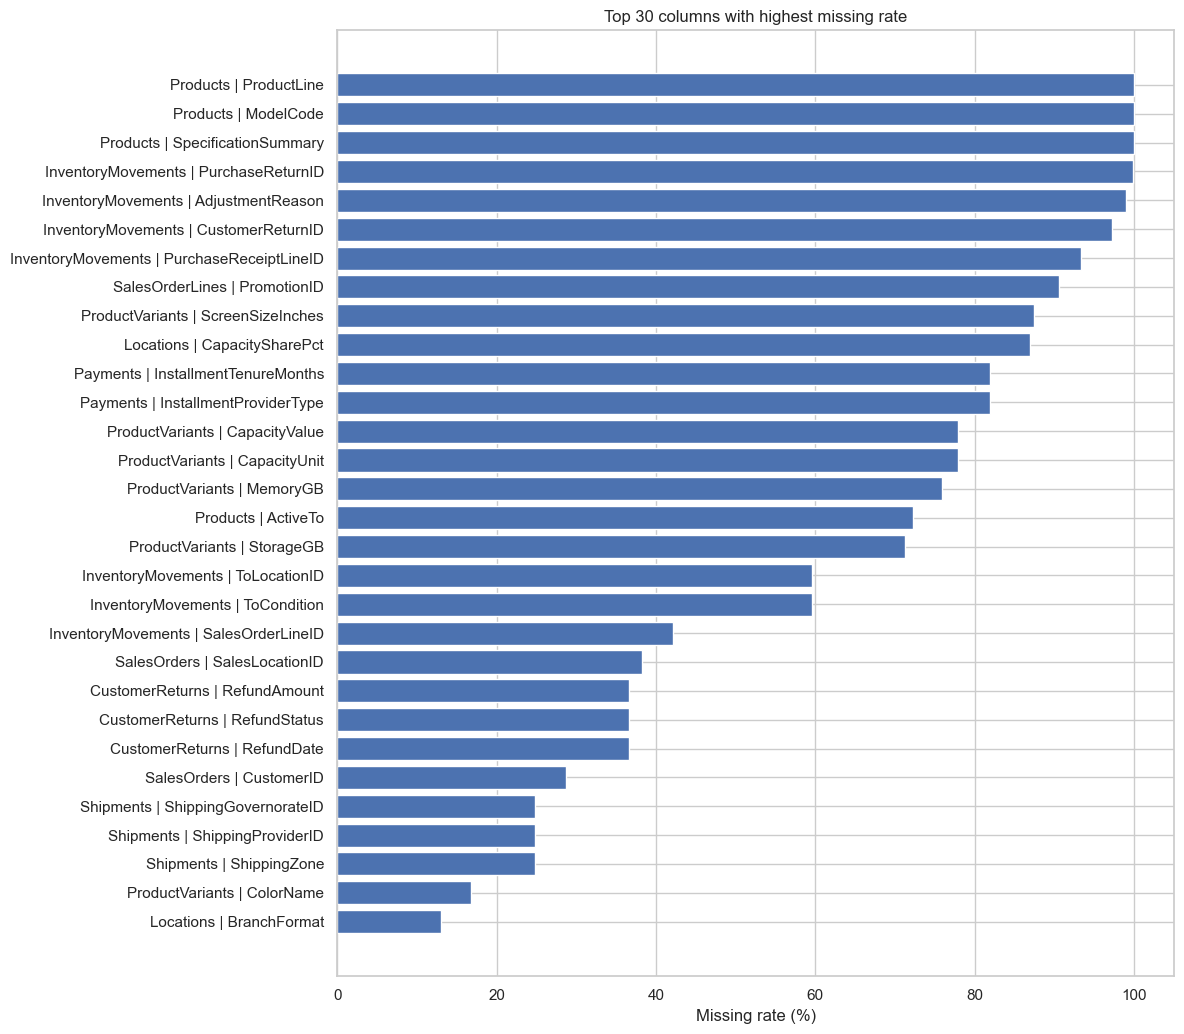

In [15]:
missing_plot_df = column_profile_df[
    column_profile_df["missing_rate_pct"] > 0
].copy()

if not missing_plot_df.empty:
    missing_plot_df = missing_plot_df.sort_values(
        "missing_rate_pct",
        ascending=True
    ).tail(30)

    plt.figure(figsize=(12, max(5, len(missing_plot_df) * 0.35)))

    labels = (
        missing_plot_df["table"].astype(str)
        + " | "
        + missing_plot_df["column"].astype(str)
    )

    plt.barh(labels, missing_plot_df["missing_rate_pct"])
    plt.xlabel("Missing rate (%)")
    plt.title("Top 30 columns with highest missing rate")
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / "01_missing_rate.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("Không có giá trị thiếu trong các bảng.")

Cell 5 – Hàm dò cột theo ngữ nghĩa

In [16]:
def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def find_column(df, candidates):
    normalized = {
        normalize_name(col): col
        for col in df.columns
    }

    # Ưu tiên khớp chính xác
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in normalized:
            return normalized[key]

    # Sau đó mới xét tên cột có chứa từ khóa
    for candidate in candidates:
        key = normalize_name(candidate)

        if len(key) < 3:
            continue

        for normalized_col, original_col in normalized.items():
            if key in normalized_col:
                return original_col

    return None


COLUMN_CANDIDATES = {
    "date": [
        "OrderDate", "Order_Date", "SalesDate", "TransactionDate",
        "CreatedAt", "Date", "SaleDate"
    ],
    "quantity": [
        "Quantity", "Qty", "SalesQuantity", "UnitsSold"
    ],
    "sku": [
        "SKU", "SKUCode", "ProductSKU", "VariantSKU"
    ],
    "inventory": [
        "Inventory", "Stock", "StockQuantity", "AvailableQuantity",
        "OnHand", "InventoryQuantity"
    ],
    "price": [
        "UnitPrice", "Price", "SellingPrice", "UnitCostAtSale"
    ],
    "discount": [
        "Discount", "DiscountRate", "DiscountAmount", "PromotionDiscount"
    ],
    "channel": [
        "SalesChannel", "Channel", "SalesLocation", "LocationName"
    ]
}


detected_columns = []

for table_name, df in tables.items():
    for semantic_name, candidates in COLUMN_CANDIDATES.items():
        col = find_column(df, candidates)

        if col is not None:
            detected_columns.append({
                "table": table_name,
                "semantic_role": semantic_name,
                "detected_column": col
            })

detected_columns_df = pd.DataFrame(detected_columns)
display(detected_columns_df)

,table,semantic_role,detected_column
0,CustomerReturns,date,ReturnDate
1,CustomerReturns,quantity,ReturnQuantity
2,Customers,date,CustomerSinceDate
3,InventoryBalances,quantity,AvailableQuantity
4,InventoryBalances,sku,SKU_ID
5,InventoryBalances,inventory,AvailableQuantity
6,InventoryMovements,date,MovementDateTime
7,InventoryMovements,quantity,Quantity
8,InventoryMovements,sku,SKU_ID
9,InventoryMovements,inventory,InventoryMovementID


Cell 6 – Phân tích sản lượng, xu hướng thời gian và SKU

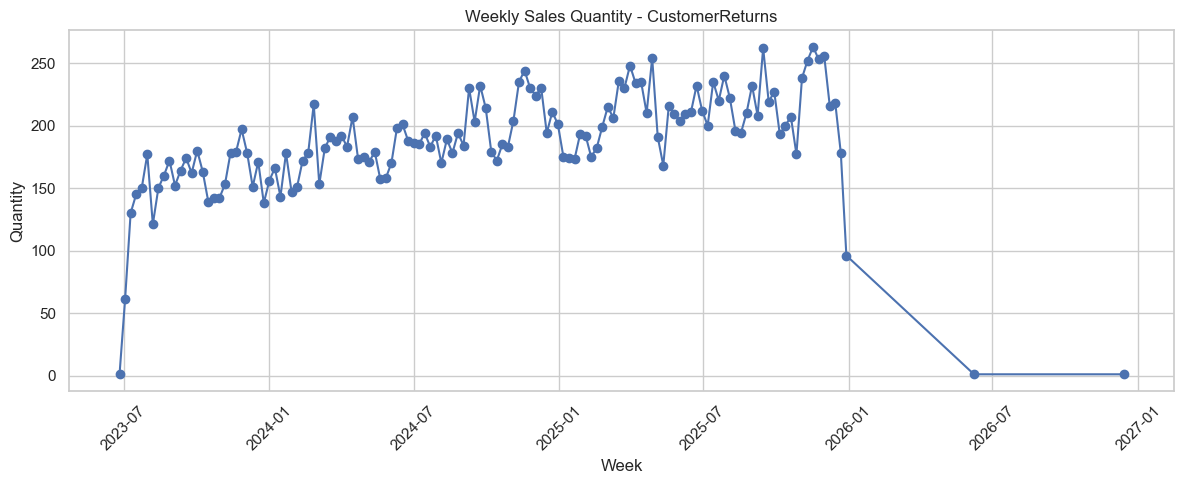

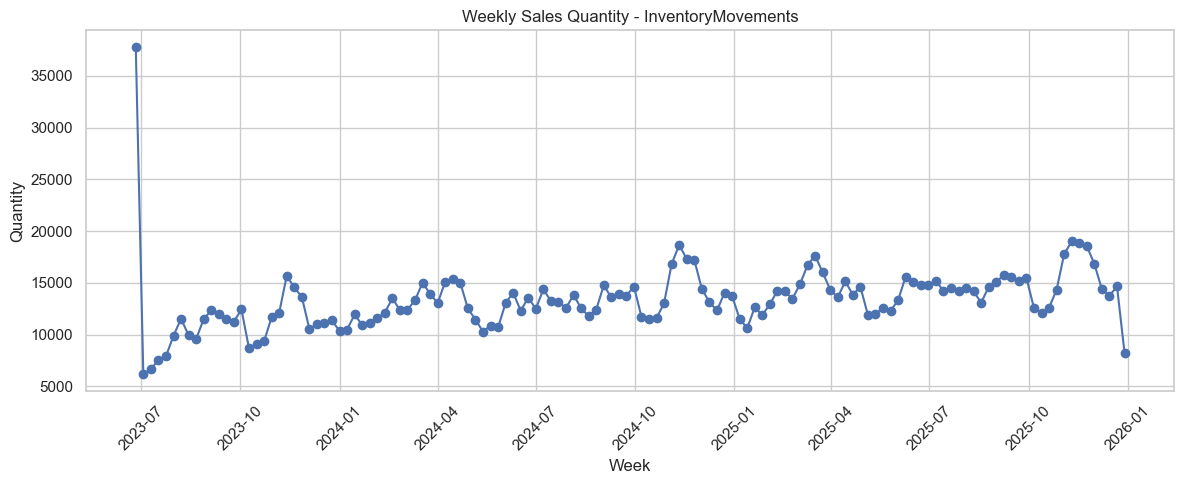

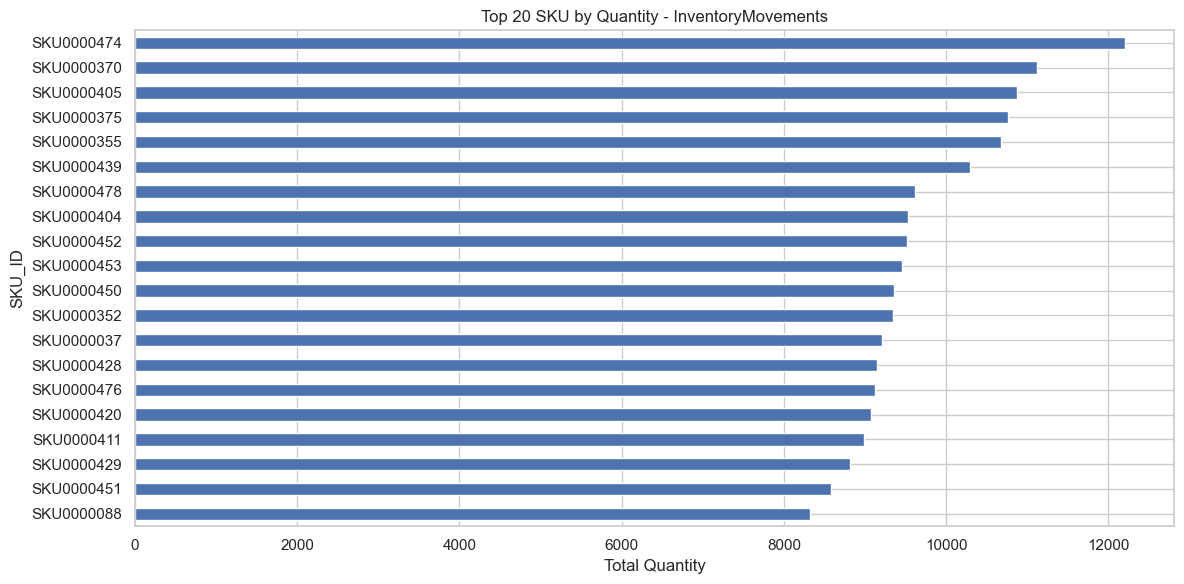

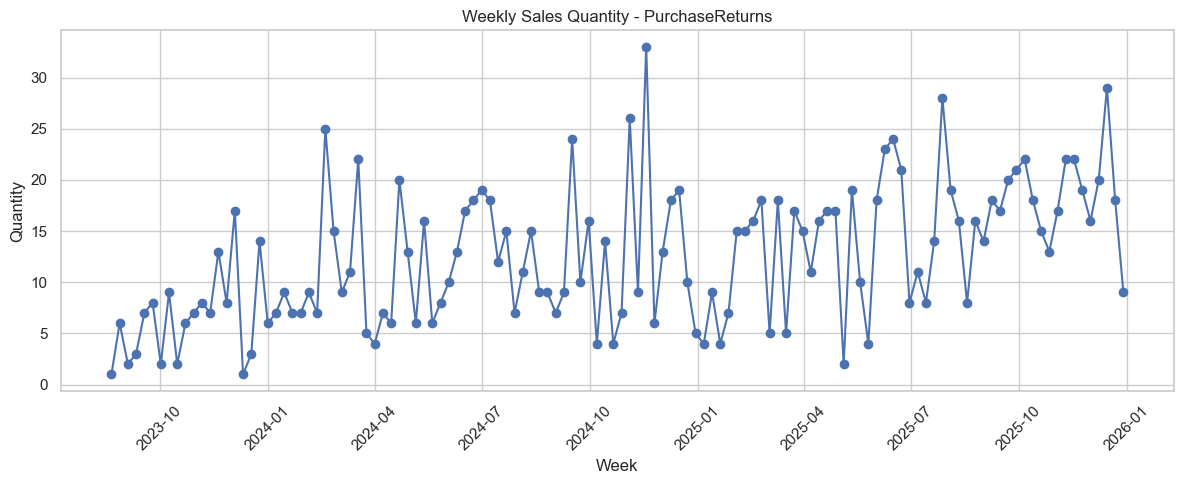

In [17]:
sales_analysis = {}

for table_name, df in tables.items():

    date_col = find_column(df, COLUMN_CANDIDATES["date"])
    qty_col = find_column(df, COLUMN_CANDIDATES["quantity"])
    sku_col = find_column(df, COLUMN_CANDIDATES["sku"])

    if date_col and qty_col:
        temp = df[[date_col, qty_col]].copy()

        temp[date_col] = pd.to_datetime(
            temp[date_col],
            errors="coerce"
        )
        temp[qty_col] = pd.to_numeric(
            temp[qty_col],
            errors="coerce"
        )

        temp = temp.dropna(subset=[date_col, qty_col])

        if not temp.empty:
            temp["week"] = (
                temp[date_col]
                .dt.to_period("W")
                .dt.start_time
            )

            weekly = (
                temp.groupby("week")[qty_col]
                .sum()
                .reset_index(name="total_quantity")
            )

            sales_analysis[table_name] = {
                "date_col": date_col,
                "quantity_col": qty_col,
                "sku_col": sku_col,
                "weekly": weekly
            }

            plt.figure(figsize=(12, 5))
            plt.plot(
                weekly["week"],
                weekly["total_quantity"],
                marker="o"
            )
            plt.title(f"Weekly Sales Quantity - {table_name}")
            plt.xlabel("Week")
            plt.ylabel("Quantity")
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"02_weekly_sales_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

            if sku_col:
                sku_temp = df[[sku_col, qty_col]].copy()
                sku_temp[qty_col] = pd.to_numeric(
                    sku_temp[qty_col],
                    errors="coerce"
                )

                sku_summary = (
                    sku_temp.groupby(sku_col)[qty_col]
                    .sum()
                    .sort_values(ascending=False)
                    .head(20)
                )

                plt.figure(figsize=(12, 6))
                sku_summary.sort_values().plot(kind="barh")
                plt.title(f"Top 20 SKU by Quantity - {table_name}")
                plt.xlabel("Total Quantity")
                plt.tight_layout()
                plt.savefig(
                    PLOT_DIR / f"03_top_sku_{table_name}.png",
                    dpi=150,
                    bbox_inches="tight"
                )
                plt.show()

if not sales_analysis:
    print(
        "Chưa tìm thấy bảng có đồng thời cột ngày và số lượng. "
        "Kiểm tra detected_columns_df và bổ sung alias trong COLUMN_CANDIDATES."
    )

Cell 7 – Phân tích phân phối Quantity, tồn kho, giá và khuyến mãi

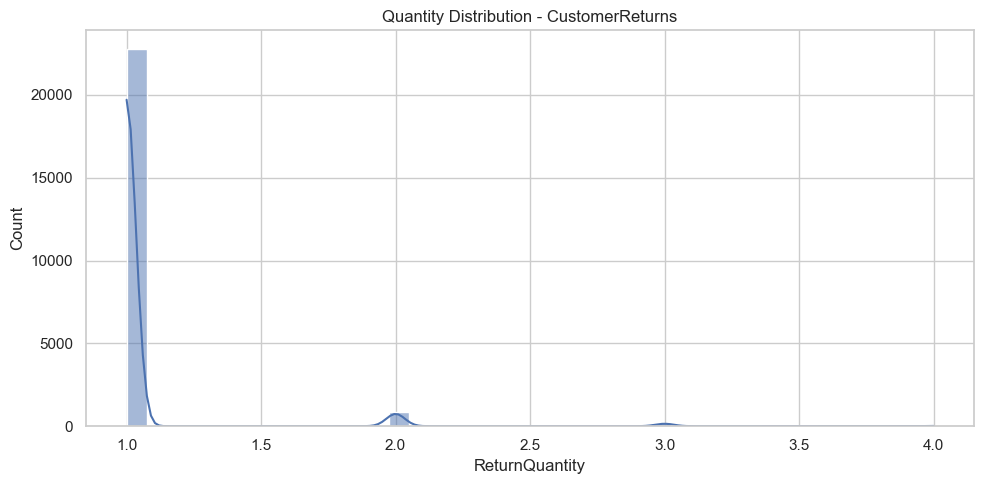

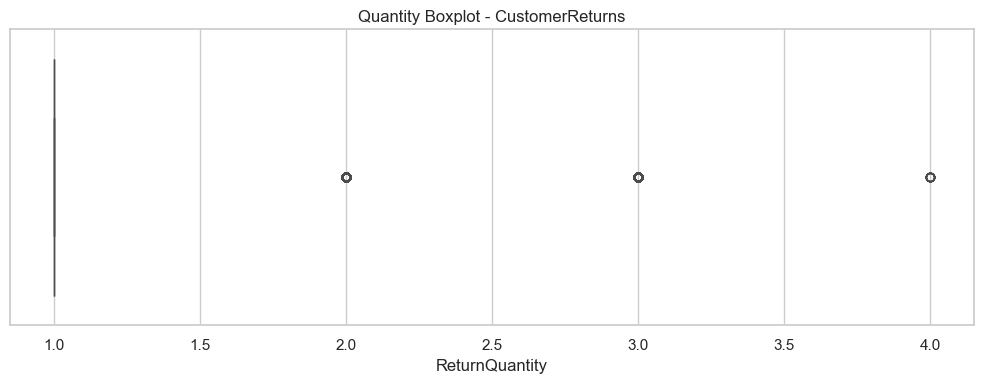

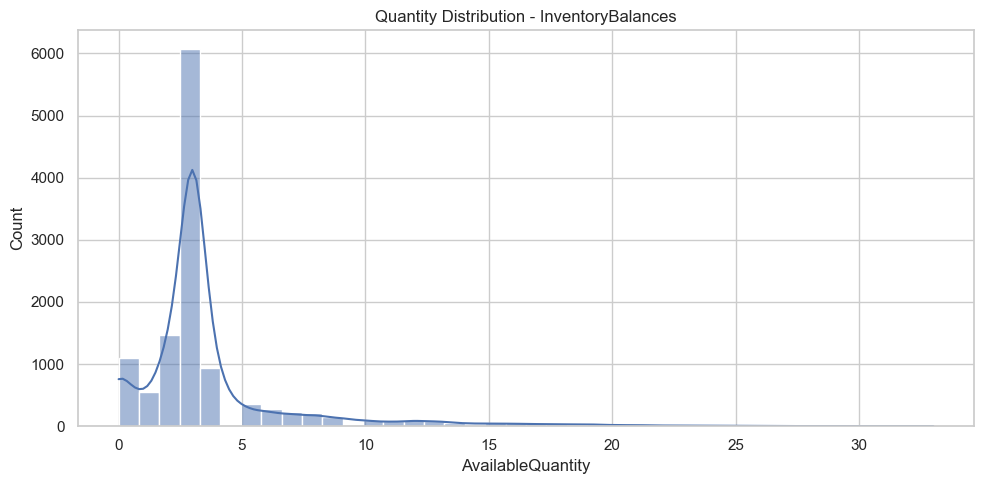

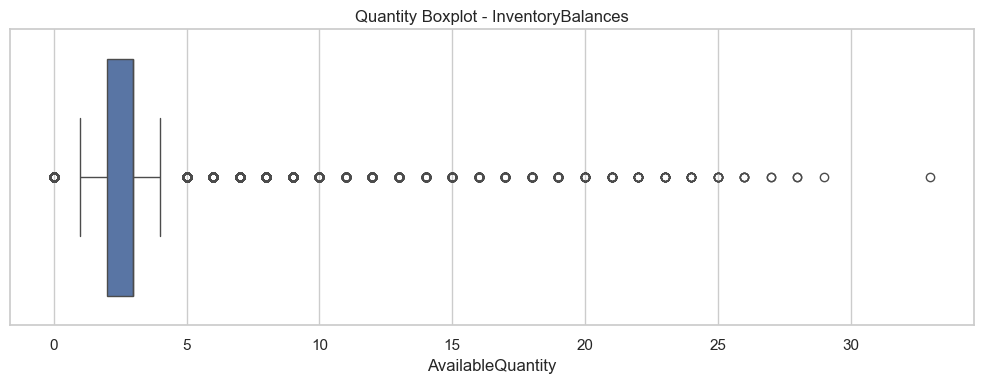

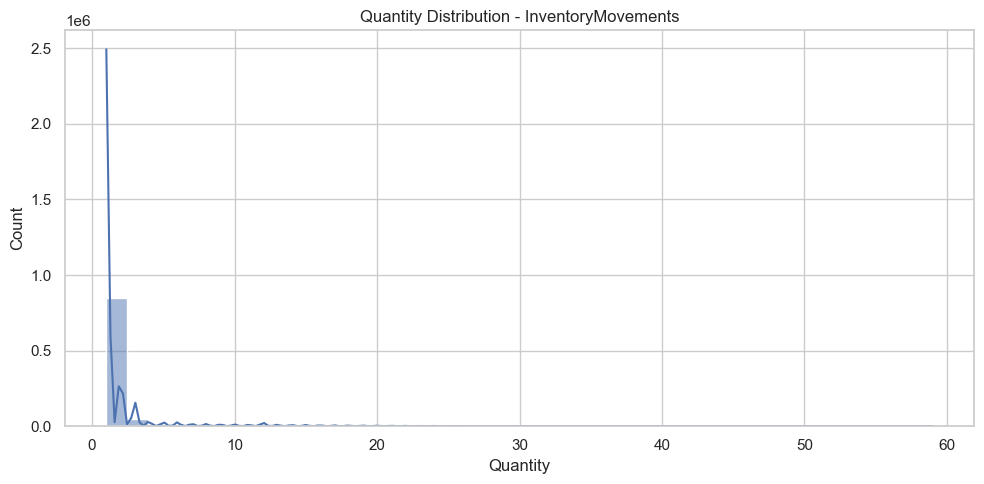

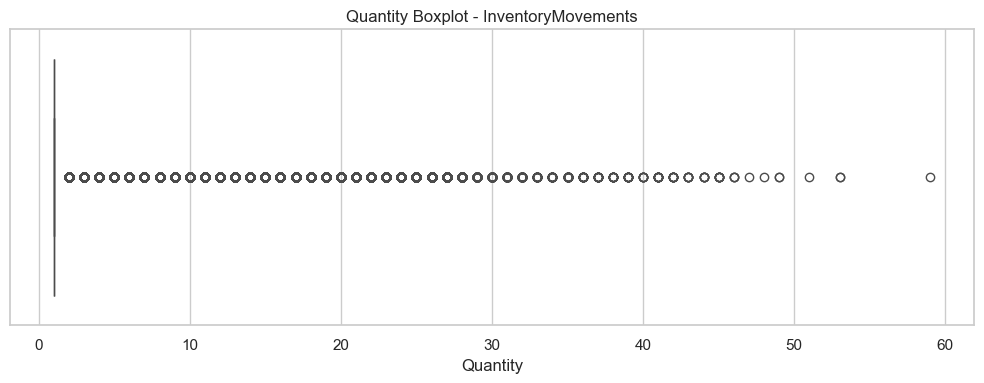

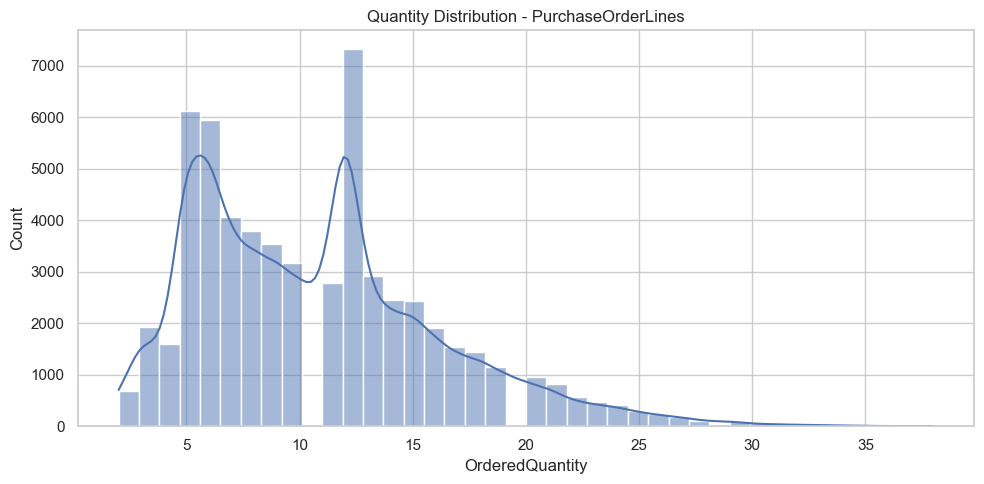

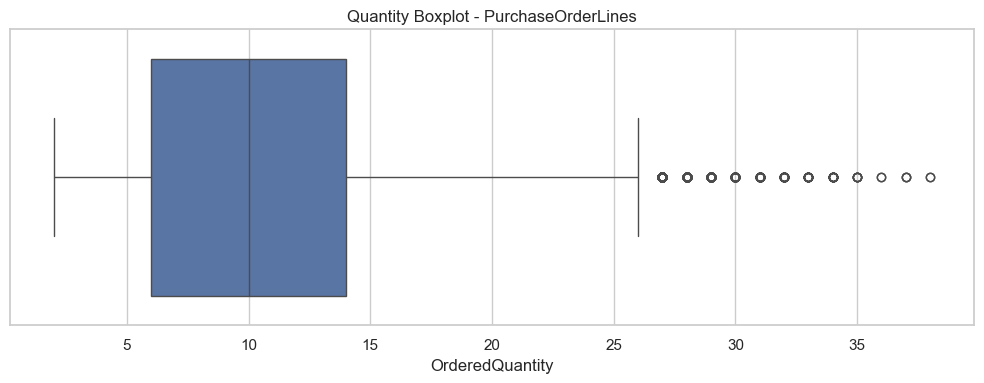

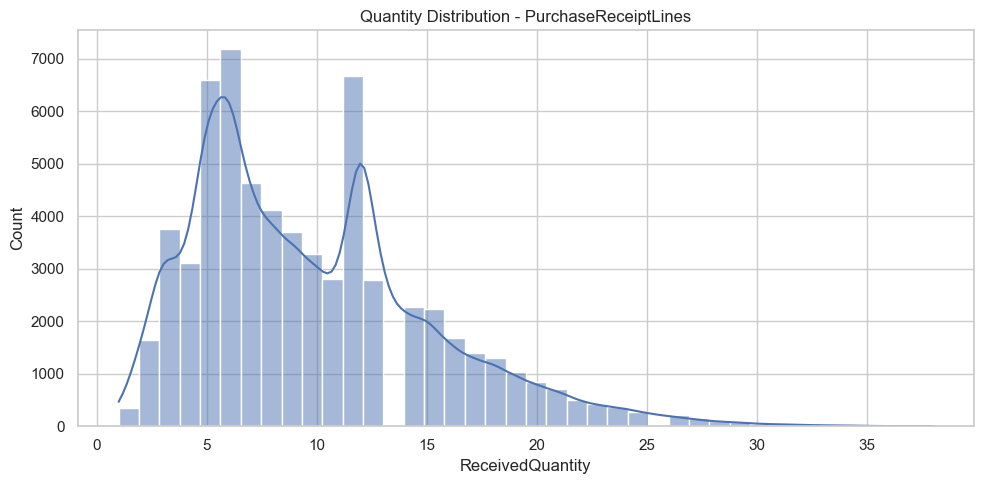

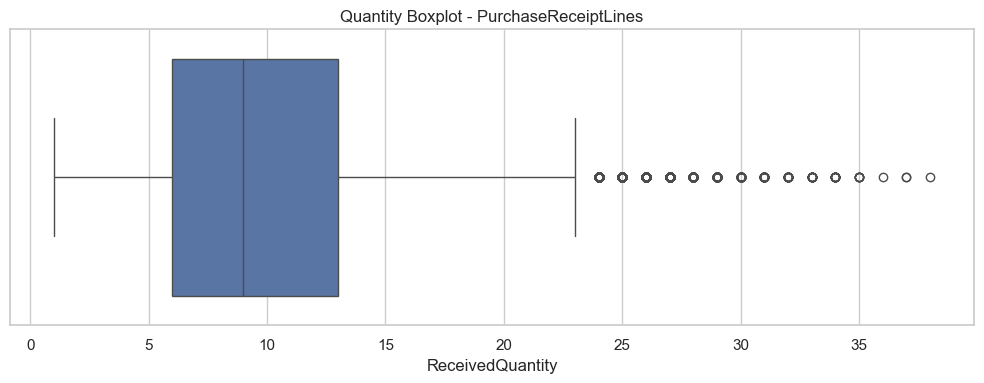

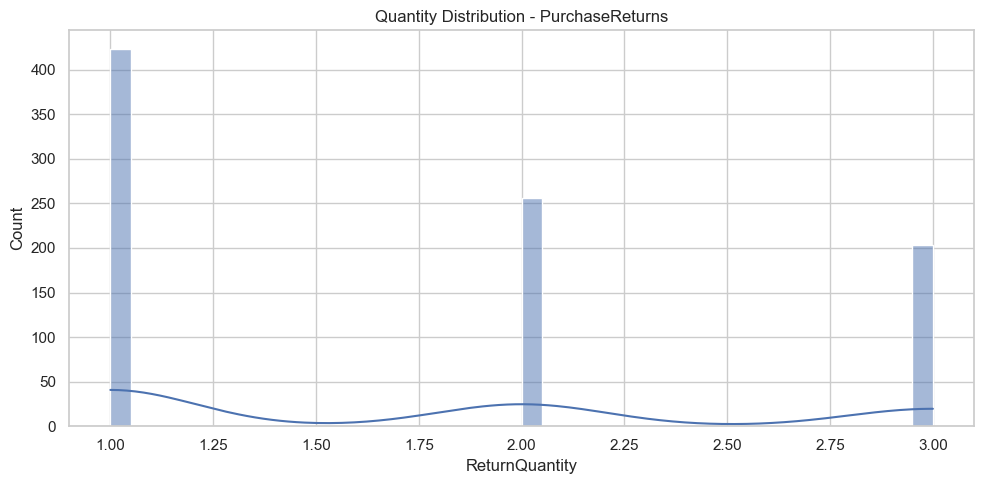

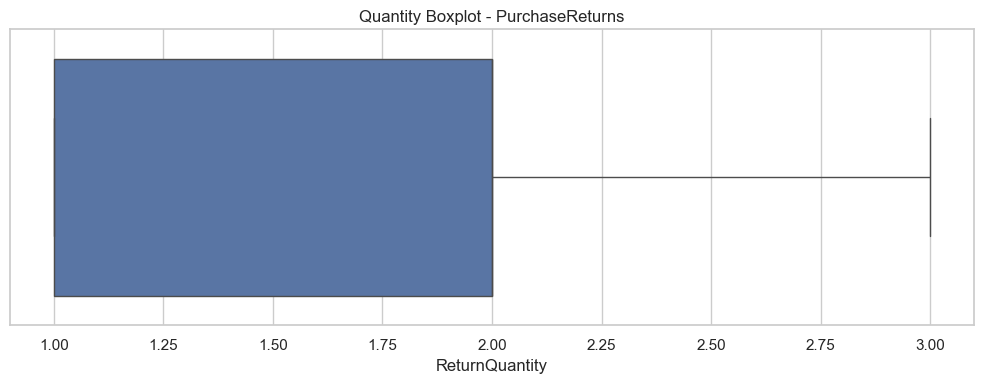

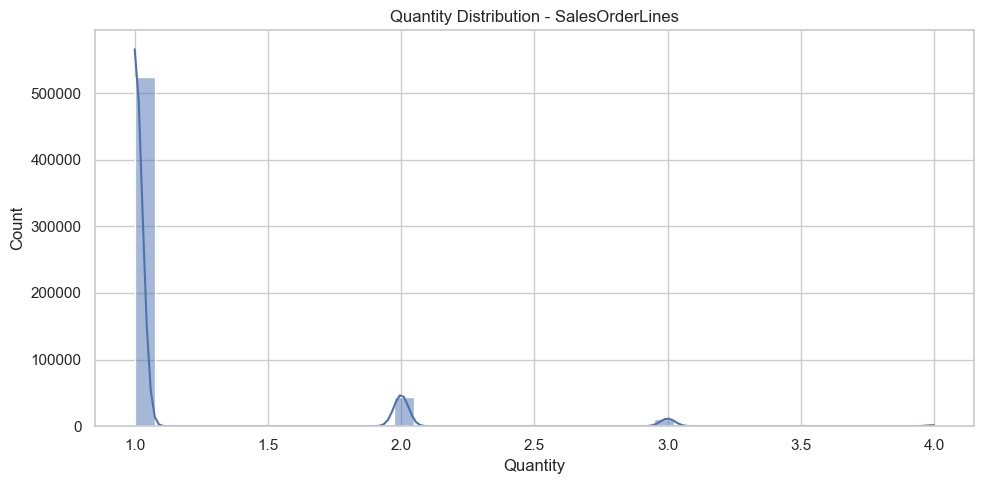

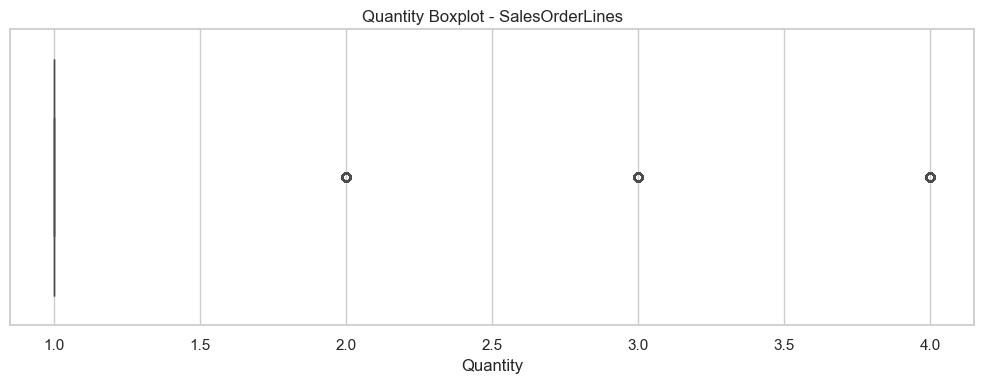

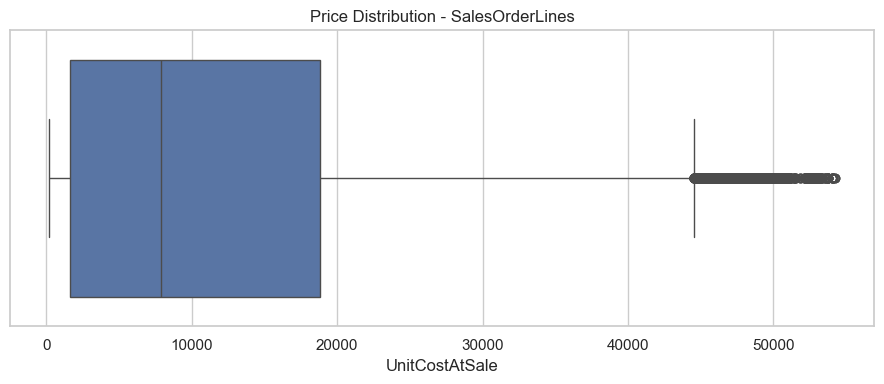

In [18]:
for table_name, df in tables.items():

    qty_col = find_column(df, COLUMN_CANDIDATES["quantity"])
    inventory_col = find_column(df, COLUMN_CANDIDATES["inventory"])
    price_col = find_column(df, COLUMN_CANDIDATES["price"])
    discount_col = find_column(df, COLUMN_CANDIDATES["discount"])

    # Quantity distribution
    if qty_col:
        values = pd.to_numeric(df[qty_col], errors="coerce").dropna()

        if not values.empty:
            plt.figure(figsize=(10, 5))
            sns.histplot(values, bins=40, kde=True)
            plt.title(f"Quantity Distribution - {table_name}")
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"04_quantity_distribution_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

            plt.figure(figsize=(10, 4))
            sns.boxplot(x=values)
            plt.title(f"Quantity Boxplot - {table_name}")
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"05_quantity_boxplot_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

    # Inventory vs Quantity
    if inventory_col and qty_col:
        if inventory_col == qty_col:
            continue

        temp = df[[inventory_col, qty_col]].copy()
        temp.columns = ["inventory", "quantity"]
        temp["inventory"] = pd.to_numeric(temp["inventory"], errors="coerce")
        temp["quantity"] = pd.to_numeric(temp["quantity"], errors="coerce")
        temp = temp.dropna(subset=["inventory", "quantity"])

        if not temp.empty:
            plt.figure(figsize=(8, 5))
            sns.scatterplot(
                data=temp,
                x="inventory",
                y="quantity",
                alpha=0.5
            )
            plt.title(f"Inventory vs Quantity - {table_name}")
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"06_inventory_vs_sales_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

    # Price distribution
    if price_col:
        values = pd.to_numeric(
            df[price_col], errors="coerce"
        ).dropna()

        if not values.empty:
            plt.figure(figsize=(9, 4))
            sns.boxplot(x=values)
            plt.title(f"Price Distribution - {table_name}")
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"07_price_boxplot_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

    # Discount distribution
    if discount_col:
        values = pd.to_numeric(
            df[discount_col], errors="coerce"
        ).dropna()

        if not values.empty:
            plt.figure(figsize=(9, 4))
            sns.histplot(values, bins=30, kde=True)
            plt.title(f"Discount Distribution - {table_name}")
            plt.tight_layout()
            plt.savefig(
                PLOT_DIR / f"08_discount_distribution_{table_name}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()

Cell 8 – Xuất báo cáo Data Understanding và Data Dictionary

In [19]:
understanding_path = REPORT_DIR / "data_understanding_report.xlsx"

with pd.ExcelWriter(
    understanding_path,
    engine="openpyxl"
) as writer:

    table_profile_df.to_excel(
        writer,
        sheet_name="Table Profile",
        index=False
    )

    column_profile_df.to_excel(
        writer,
        sheet_name="Column Profile",
        index=False
    )

    data_dictionary_df.to_excel(
        writer,
        sheet_name="Data Dictionary",
        index=False
    )

    numeric_summary_df.to_excel(
        writer,
        sheet_name="Numeric Summary",
        index=False
    )

    categorical_summary_df.to_excel(
        writer,
        sheet_name="Categorical Summary",
        index=False
    )

    detected_columns_df.to_excel(
        writer,
        sheet_name="Detected Columns",
        index=False
    )

print("Đã xuất:", understanding_path)
print("Biểu đồ được lưu tại:", PLOT_DIR)

Đã xuất: C:\Users\admin\Downloads\important\SKU-Weekly-Sales-Forecasting\reports\data_understanding_report.xlsx
Biểu đồ được lưu tại: C:\Users\admin\Downloads\important\SKU-Weekly-Sales-Forecasting\plots
